# Trajectory Visualization -- Module 1 + 2 + 3 Combined Output

Saves labeled panel figures of Module 2's synthesized multi-stage trajectory, with Module 3's
per-step "probability of further progression within 2 years" captioned beneath each panel.

`train_module2_poc.py` only saves a single-step training-sanity strip, and
`evaluate_trajectory.py` reduces the synthesized images straight to PSNR/SSIM/FID numbers
without saving them. This notebook is what keeps the actual images (and Module 3's estimate on
each one).

**Run this after notebooks 05, 06, AND 07 have all finished** -- it reads the Module 1 cache,
the trained Module 2 Generator checkpoint, and the trained Module 3 checkpoint + its saved LBS
thresholds, all from Drive/the current runtime's local outputs.

Module 3 estimates a probability within a fixed 2-year horizon, never an exact date. Every
synthesized (non-baseline) panel's Module 3 estimate is captioned "(synthesized image --
untested)" -- Module 3 is trained only on real photographs, so running it on Module 2's
synthesized output is mechanically possible but was not part of its training distribution.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
# Free Drive space: the training notebooks save checkpoints and caches here (several GB in total).
# Deleted or overwritten files stay in the Drive Trash and still count -- empty it if space is low.
import shutil as _shutil
try:
    _du = _shutil.disk_usage('/content/drive/MyDrive')
    print(f'Google Drive: {_du.free / 1e9:.1f} GB free of {_du.total / 1e9:.1f} GB')
    if _du.free < 10e9:
        print('⚠ Under 10 GB free on Google Drive -- model files may fail to save. Empty the Trash '
              '(drive.google.com/drive/trash) or free space before training.')
except OSError:
    pass

import getpass, os
GITHUB_TOKEN = getpass.getpass('GitHub Personal Access Token (repo scope): ')

REPO_OWNER = 'Mieka068'
REPO_NAME = 'DRProgression'
REPO_BRANCH = 'mod-2-NonLongIntegration'  # <-- has --end-stage; 'main' once merged
REPO_CODE_SUBDIR = 'M2-DRProgression-VerM-module1-fgadr-poc'

DRIVE_DATA_DIR = '/content/drive/MyDrive/Thesis_Datasets'
assert os.path.isdir(DRIVE_DATA_DIR), f"Not found: {DRIVE_DATA_DIR}"

# Which Module 1 models the pipeline uses -- set the SAME value in notebooks 04_05 and 06-10:
#   'drgnet' -- notebook 11's DRG-Net replication checkpoints (module1_runs/drgnet_replication/)
#   'poc'    -- notebooks 02/03's original POC checkpoints (module1_runs/)
# Everything built from Module 1's outputs (Module 1 caches, Module 2 runs, figures) gets a
# '_drgnet' suffix for 'drgnet', so the two pipelines never overwrite each other's results.
MODULE1_SOURCE = 'drgnet_combined'
assert MODULE1_SOURCE in ('drgnet_combined', 'drgnet', 'poc'), MODULE1_SOURCE
RUN_TAG = {'drgnet_combined': '_drgnet_comb', 'drgnet': '_drgnet', 'poc': ''}[MODULE1_SOURCE]
MODULE1_RUNS = os.path.join(DRIVE_DATA_DIR, 'module1_runs', *(['drgnet_replication'] if MODULE1_SOURCE != 'poc' else []))
# Lesion segmenters: <MODULE1_RUNS>/segmentation/<SEG_MODEL_PREFIX><lesion>/model_2.pth.tar --
# FGADR + DDR combined (notebook 11) or FGADR only. The classifier is FGADR's either way.
SEG_MODEL_PREFIX = 'comb_models_' if MODULE1_SOURCE == 'drgnet_combined' else 'models_FGADR_NO_TATL_'
MODULE1_CACHE_DIR = os.path.join(DRIVE_DATA_DIR, 'module1_cache' + RUN_TAG)
os.makedirs(MODULE1_CACHE_DIR, exist_ok=True)
print('Module 1 source:', MODULE1_SOURCE, '| models:', MODULE1_RUNS, '| caches:', MODULE1_CACHE_DIR)
TIANJIN_CACHE = os.path.join(MODULE1_CACHE_DIR, 'module1_outputs_tianjin.pt')
assert os.path.isfile(TIANJIN_CACHE), f"Not found: {TIANJIN_CACHE} -- run notebook 04_05 first (same MODULE1_SOURCE)."

Mounted at /content/drive
Google Drive: 173.7 GB free of 214.7 GB
GitHub Personal Access Token (repo scope): ··········
Module 1 source: drgnet_combined | models: /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication | caches: /content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb


In [2]:
# Unzip Tianjin locally (same convention as notebooks 05/06/07).
import glob

os.makedirs('/content/data', exist_ok=True)
%cd /content/data
!unzip -q -n "$DRIVE_DATA_DIR/retinal-dr-longitudinal.zip" -d _tianjin_extract_raw

_manifest_candidates = glob.glob('/content/data/_tianjin_extract_raw/**/corrected_manifest.csv', recursive=True)
assert _manifest_candidates, 'No corrected_manifest.csv found -- see notebook 05 for troubleshooting.'
_tianjin_root = os.path.dirname(_manifest_candidates[0])
TIANJIN_DIR = '/content/data/retinal-dr-longitudinal'
if _tianjin_root != TIANJIN_DIR and not os.path.exists(TIANJIN_DIR):
    os.symlink(_tianjin_root, TIANJIN_DIR)

# Same laterality-resolution fetch-or-compute as notebooks 05/06/07 -- required by
# tianjin_dataset.py / module3/dataset.py.
LATERALITY_DRIVE_PATH = os.path.join(DRIVE_DATA_DIR, 'module1_cache', 'laterality_resolved.csv')
LATERALITY_LOCAL_PATH = os.path.join(TIANJIN_DIR, 'laterality_resolved.csv')
assert os.path.isfile(LATERALITY_DRIVE_PATH), (
    f"Not found: {LATERALITY_DRIVE_PATH} -- run notebook 05 first (it computes and persists this)."
)
import shutil
shutil.copy(LATERALITY_DRIVE_PATH, LATERALITY_LOCAL_PATH)
print('Tianjin manifest found:', os.path.isfile(os.path.join(TIANJIN_DIR, 'corrected_manifest.csv')))

/content/data
Tianjin manifest found: True


In [3]:
# Clone this repo. Skips cleanly if already cloned in this runtime.
%cd /content
if not os.path.isdir(f'/content/{REPO_NAME}'):
    !git clone --branch {REPO_BRANCH} https://{GITHUB_TOKEN}@github.com/{REPO_OWNER}/{REPO_NAME}.git {REPO_NAME}

REPO_CODE_DIR = f'/content/{REPO_NAME}/{REPO_CODE_SUBDIR}'
assert os.path.isdir(REPO_CODE_DIR), f"Not found: {REPO_CODE_DIR} -- check REPO_BRANCH/REPO_CODE_SUBDIR above"

%cd {REPO_CODE_DIR}
!pip install -q pandas openpyxl segmentation-models-pytorch matplotlib

/content
Cloning into 'DRProgression'...
remote: Enumerating objects: 620, done.
remote: Counting objects: 100% (299/299), done.
remote: Compressing objects: 100% (215/215), done.
remote: Total 620 (delta 174), reused 184 (delta 84), pack-reused 321 (from 1)
Receiving objects: 100% (620/620), 9.30 MiB | 22.41 MiB/s, done.
Resolving deltas: 100% (344/344), done.
/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 16.1 MB/s eta 0:00:00


In [4]:
# Locate the Module 1 classifier + EX/MA (+ HE/SE if trained) checkpoints, same discovery
# logic as notebooks 04/05/06.
import glob

SEG_DIR   = os.path.join(MODULE1_RUNS, 'segmentation')
CLS_SAVES = os.path.join(MODULE1_RUNS, 'classification', 'fgadr', 'saves')

_pref  = ['final_weights.pt', 'best_validation_weights.pt']
_cands = [os.path.join(CLS_SAVES, n) for n in _pref] + sorted(
    glob.glob(os.path.join(CLS_SAVES, '*.pt')), key=os.path.getmtime, reverse=True)
CLS_CKPT = next((p for p in _cands if os.path.isfile(p)), None)
assert CLS_CKPT, f"No classifier .pt in {CLS_SAVES} -- run notebook 02/03 (MODULE1_SOURCE='poc') or 11 ('drgnet' / 'drgnet_combined') first"

EX_CKPT = os.path.join(SEG_DIR, SEG_MODEL_PREFIX + 'ex', 'model_2.pth.tar')
MA_CKPT = os.path.join(SEG_DIR, SEG_MODEL_PREFIX + 'ma', 'model_2.pth.tar')
for _p in (CLS_CKPT, EX_CKPT, MA_CKPT):
    assert os.path.isfile(_p), f"missing checkpoint: {_p} -- run notebook 02/03 (MODULE1_SOURCE='poc') or 11 ('drgnet' / 'drgnet_combined') first"

HE_CKPT = os.path.join(SEG_DIR, SEG_MODEL_PREFIX + 'he', 'model_2.pth.tar')
SE_CKPT = os.path.join(SEG_DIR, SEG_MODEL_PREFIX + 'se', 'model_2.pth.tar')
_extra_seg_args = ''
if os.path.isfile(HE_CKPT):
    _extra_seg_args += f' --seg-checkpoint HE={HE_CKPT}'
if os.path.isfile(SE_CKPT):
    _extra_seg_args += f' --seg-checkpoint SE={SE_CKPT}'
print('classifier :', CLS_CKPT)
print('EX seg     :', EX_CKPT)
print('MA seg     :', MA_CKPT)
print('HE seg     :', HE_CKPT if os.path.isfile(HE_CKPT) else 'not trained yet')
print('SE seg     :', SE_CKPT if os.path.isfile(SE_CKPT) else 'not trained yet')

# Module 2 + Module 3 checkpoints, from notebooks 06 and 07's local runtime outputs (or copy
# them here from Drive first if this is a fresh runtime from those notebooks).
# Module 2 Generator from notebook 06 (same MODULE1_SOURCE): Drive copy first, then this runtime;
# the EyePACS-pretrained run before the random-init ablation.
# best-G.ckpt (best epoch on held-out pairs) before final-G.ckpt (last epoch).
_gen_cands = [os.path.join(base, run + RUN_TAG, ckpt)
              for run in ('models_poc_tianjin_from_nonlong', 'models_poc_tianjin')
              for base in (os.path.join(DRIVE_DATA_DIR, 'module2_runs'), f'{REPO_CODE_DIR}/DRForestGAN-v2/stargan')
              for ckpt in ('best-G.ckpt', 'final-G.ckpt')]
GENERATOR_CKPT = next((p for p in _gen_cands if os.path.isfile(p)), _gen_cands[0])
print('generator :', GENERATOR_CKPT)
# Module 3 from notebook 07 (same MODULE1_SOURCE): its Drive copy first, then this runtime.
_m3_dir = next((d for d in (os.path.join(DRIVE_DATA_DIR, 'module3_runs', 'module3_runs_poc' + RUN_TAG),
                            f'{REPO_CODE_DIR}/module3/module3_runs_poc')
                if os.path.isfile(os.path.join(d, 'final-model.ckpt'))),
               os.path.join(DRIVE_DATA_DIR, 'module3_runs', 'module3_runs_poc' + RUN_TAG))
MODULE3_CKPT = next((os.path.join(_m3_dir, c) for c in ('best-model.ckpt', 'final-model.ckpt')
                     if os.path.isfile(os.path.join(_m3_dir, c))), os.path.join(_m3_dir, 'final-model.ckpt'))
MODULE3_RESULTS_JSON = os.path.join(_m3_dir, 'poc_results.json')
print('module 3  :', MODULE3_CKPT)
for _p in (GENERATOR_CKPT, MODULE3_CKPT, MODULE3_RESULTS_JSON):
    assert os.path.isfile(_p), (
        f"Not found: {_p} -- run notebook 06 (Module 2) and notebook 07 (Module 3) first, "
        "with the same MODULE1_SOURCE."
    )
# Figures go to Drive (the runtime disk is wiped when the session ends).
TRAJ_FIG_DIR = os.path.join(DRIVE_DATA_DIR, 'module2_runs', 'trajectory_figures' + RUN_TAG)
os.makedirs(TRAJ_FIG_DIR, exist_ok=True)

classifier : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication/classification/fgadr/saves/final_weights.pt
EX seg     : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication/segmentation/comb_models_ex/model_2.pth.tar
MA seg     : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication/segmentation/comb_models_ma/model_2.pth.tar
HE seg     : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication/segmentation/comb_models_he/model_2.pth.tar
SE seg     : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication/segmentation/comb_models_se/model_2.pth.tar
generator : /content/drive/MyDrive/Thesis_Datasets/module2_runs/models_poc_tianjin_from_nonlong_drgnet_comb/best-G.ckpt
module 3  : /content/drive/MyDrive/Thesis_Datasets/module3_runs/module3_runs_poc_drgnet_comb/best-model.ckpt


In [5]:
# END_STAGE = None stops each patient at their real follow-up grade (original behaviour);
# END_STAGE = 4 cascades every patient all the way to PDR. (Any image, not just Tianjin:
# notebook 10.)
END_STAGE = None
_end_stage_arg = f' --end-stage {END_STAGE}' if END_STAGE is not None else ''
%cd {REPO_CODE_DIR}
!python visualize_trajectory.py \
    --tianjin-dir "{TIANJIN_DIR}" \
    --tianjin-module1-cache "{TIANJIN_CACHE}" \
    --generator-checkpoint "{GENERATOR_CKPT}" \
    --classifier-checkpoint "{CLS_CKPT}" \
    --seg-checkpoint EX="{EX_CKPT}" --seg-checkpoint MA="{MA_CKPT}"{_extra_seg_args} \
    --module3-checkpoint "{MODULE3_CKPT}" \
    --module3-thresholds-json "{MODULE3_RESULTS_JSON}" \
    --num-patients 4{_end_stage_arg} \
    --out-dir "{TRAJ_FIG_DIR}"

/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc
Device: cuda

[1/4] Loading Tianjin survival dataset (source of real progression pairs)...
✓ Loaded Module 1 cache: 1234 images (/content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb/module1_outputs_tianjin.pt)
  Total eye-pairs in corrected_manifest.csv: 1115
  Baseline sheet 'Baseline': patient_id <- 'ID', OS <- 'OS Grade（1=No Apparent Retinopathy；2=Mild Non-Proliferative Diabetic Retinopathy；3=Moderate Non-Proliferative Diabetic Retinopathy；4=Severe Non-Proliferative Diabetic Retinopathy；5=Proliferative Diabetic Retinopathy；6=After laser；7=Missing）', OD <- 'OD Grade（1=No Apparent Retinopathy；2=Mild Non-Proliferative Diabetic Retinopathy；3=Moderate Non-Proliferative Diabetic Retinopathy；4=Severe Non-Proliferative Diabetic Retinopathy；5=Proliferative Diabetic Retinopathy；6=After laser；7=Missing）', worse-eye <- 'At-risk Eye Grade（Worse eye）'
  Follow-up sheet '2 year follow-up': patient_id <- 'ID', OS <- 'OS Grad

4 figure(s) saved:
  /content/drive/MyDrive/Thesis_Datasets/module2_runs/trajectory_figures_drgnet_comb/patient_349_OD.png


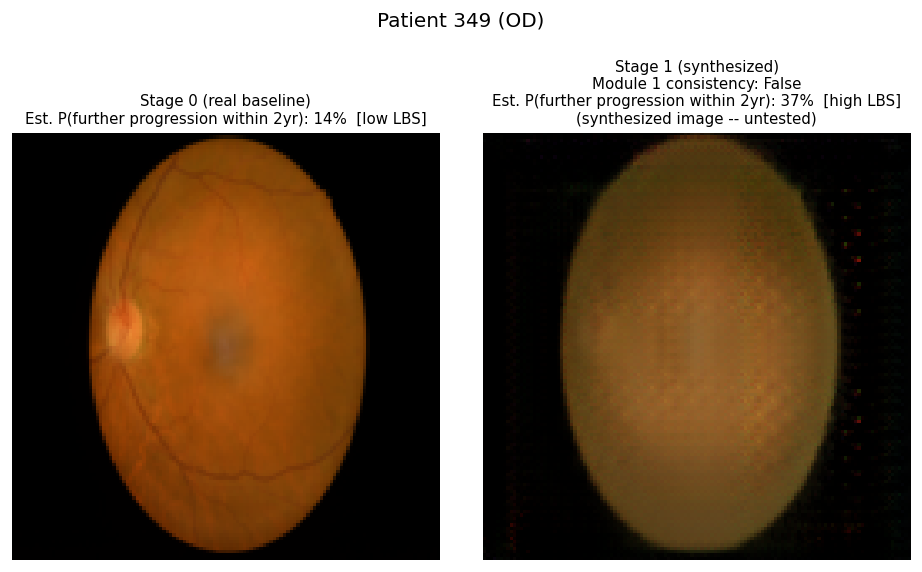

  /content/drive/MyDrive/Thesis_Datasets/module2_runs/trajectory_figures_drgnet_comb/patient_398_OD.png


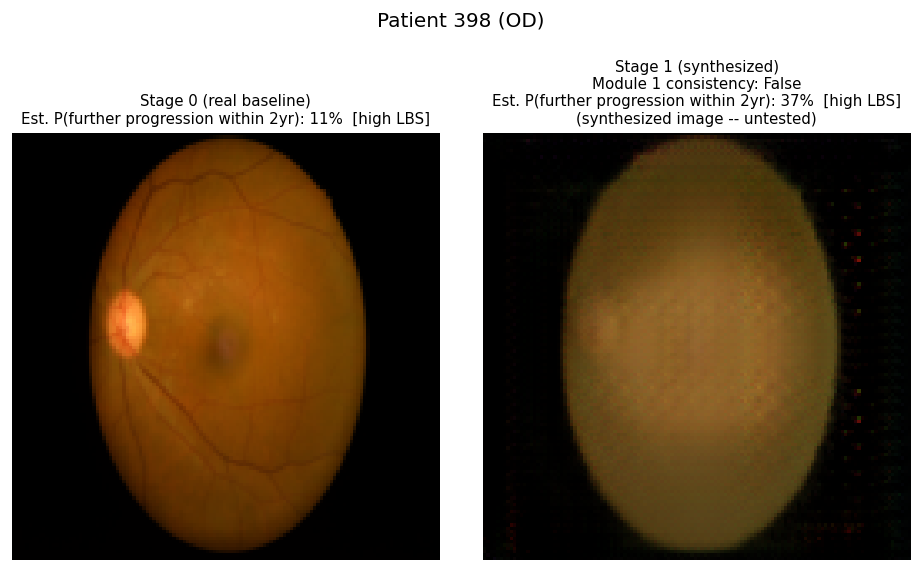

  /content/drive/MyDrive/Thesis_Datasets/module2_runs/trajectory_figures_drgnet_comb/patient_398_row38.png


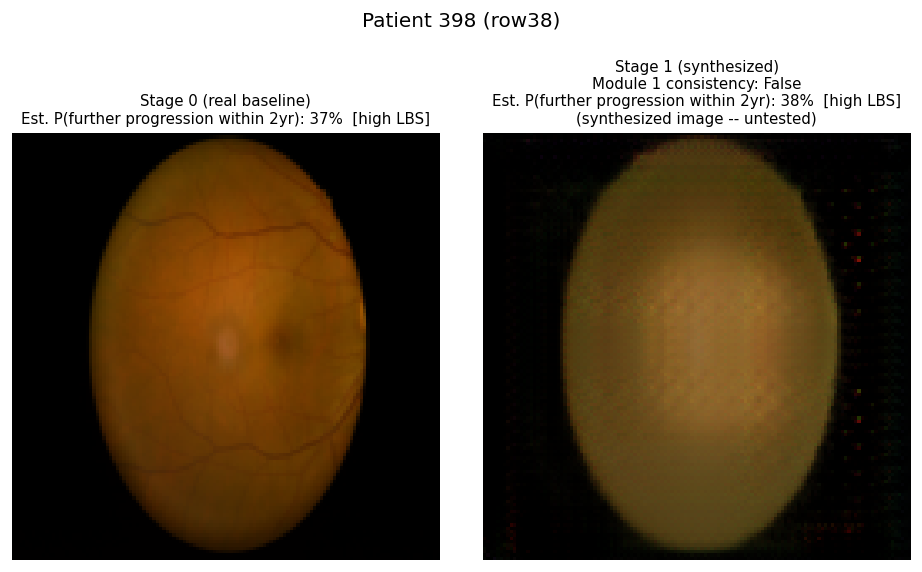

  /content/drive/MyDrive/Thesis_Datasets/module2_runs/trajectory_figures_drgnet_comb/patient_439_OD.png


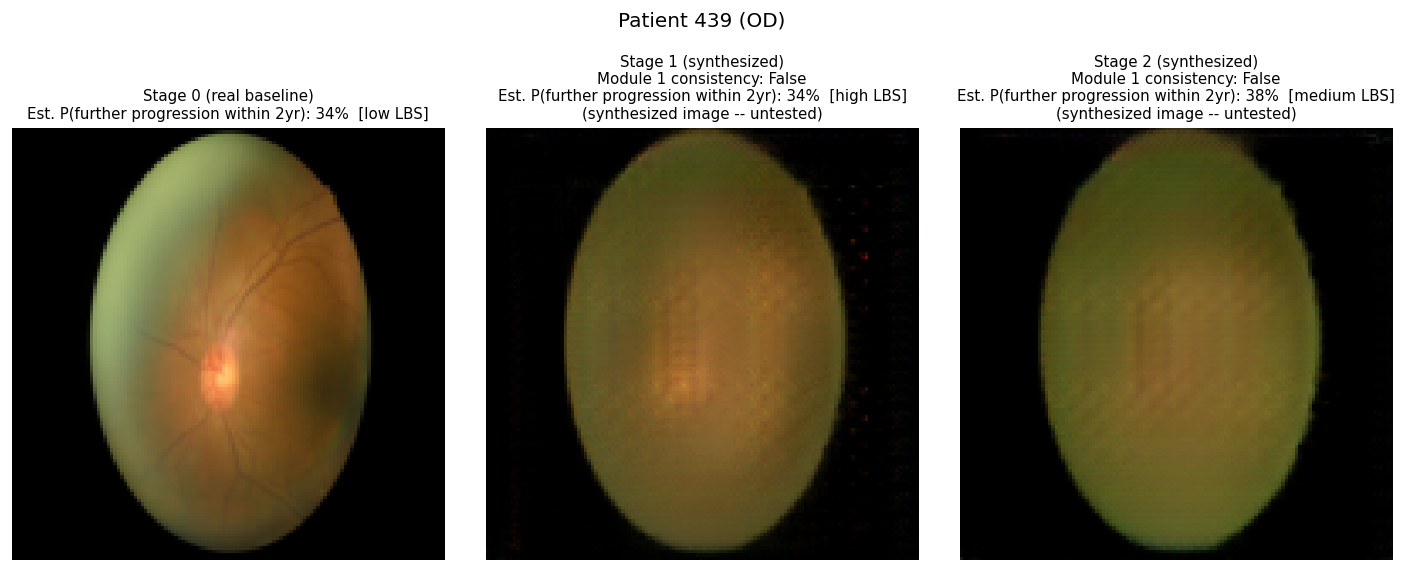

In [6]:
from IPython.display import Image as IPImage, display
import glob

figures = sorted(glob.glob(f'{TRAJ_FIG_DIR}/patient_*.png'))
print(f'{len(figures)} figure(s) saved:')
for fig_path in figures:
    print(' ', fig_path)
    display(IPImage(fig_path))

## Caveats

- These figures show real progression pairs from Tianjin only (patients whose real follow-up
  grade is higher than their real baseline grade) -- the cascade is only defined for
  progression, not regression or no-change.
- Module 3's caption is "estimated probability of further progression within 2 years," never
  a specific date -- that is the only horizon the model has real training signal for.
- Every synthesized (non-baseline) panel's Module 3 estimate is marked "(synthesized image --
  untested)": Module 3 is trained only on real baseline photographs, and running it on a
  Module-2-synthesized image is mechanically possible but was not part of its training
  distribution.
- Module 1's "consistency" flag on each synthesized panel means the re-graded synthesized
  image matches the intended target stage -- a False here could mean the generator produced
  something implausible, or that Module 1's own grader is unreliable on synthesized
  (out-of-distribution) images, or both.

## Before closing the runtime

Files written to Drive upload in the background. Run this last cell and wait for the ✓ before
disconnecting or deleting the runtime -- otherwise large files written at the end (model weights,
caches) can be lost.

In [7]:
from google.colab import drive
drive.flush_and_unmount()
print('✓ Everything is uploaded to Google Drive -- safe to disconnect the runtime.')

✓ Everything is uploaded to Google Drive -- safe to disconnect the runtime.
